# Phase 2 — Structured Travel State

* Define the shared `TravelState`.
* Extract and maintain structured user requirements.
* Update the `TravelState` across interactions.

In [ ]:
# Imports and environment setup

import os
import json
import uuid
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display, Markdown
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, ToolMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from pydantic import BaseModel, Field

load_dotenv(override=True)

True

## Define the shared `TravelState`

In [ ]:
# Define the shared TravelState
class TravelRequirements(BaseModel):
    origin: str | None = None
    destination: str | None = None
    travel_dates: str | None = None
    duration_days: int | None = None
    travelers: int | None = None
    budget: float | None = None
    currency: str | None = None
    interests: list[str] = Field(default_factory=list)
    constraints: list[str] = Field(default_factory=list)

class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None

## Tool for updating the travel state

In [3]:
def normalize_list(value: list[str] | str | None) -> list[str]:
    """
    Normalize a value into a list of strings.

    Accepts None, an existing list, or a JSON-encoded list returned as a string.
    If the string is not valid JSON, it is treated as a single list item.
    """
    if value is None:
        return []

    if isinstance(value, list):
        return value

    # The model may return the list as a JSON-encoded string.
    if isinstance(value, str):
        try:
            parsed = json.loads(value)

            # Return the parsed value if it is a valid JSON list.
            if isinstance(parsed, list):
                return parsed

        except json.JSONDecodeError:
            pass

        return [value]

    # Fallback for unexpected input types.
    return []

In [14]:
@tool
def update_requirements(
    runtime: ToolRuntime,
    origin: str | None = None,
    destination: str | None = None,
    travel_dates: str | None = None,
    duration_days: int | None = None,
    travelers: int | None = None,
    budget: float | None = None,
    currency: str | None = None,
    add_interests: list[str] | str | None = None,
    remove_interests: list[str] | str | None = None,
    add_constraints: list[str] | str | None = None,
    remove_constraints: list[str] | str | None = None,
) -> Command:
    """
    Update the user's current travel requirements.

    Only provide fields that have been explicitly added or changed by the user.

    For interests and constraints:
    - Use add_interests to add new interests.
    - Use remove_interests to remove previous interests.
    - Use add_constraints to add new constraints.
    - Use remove_constraints to remove previous constraints.

    Do not invent requirements or modify information that the user has not
    explicitly changed.
    """

    # ToolRuntime gives the tool access to the current LangGraph state,
    # including the TravelRequirements stored in the current graph execution.
    current = runtime.state["requirements"]

    if current is None:
        current = TravelRequirements()

    updated = current.model_copy()

    # Normalize list arguments in case the model sends JSON strings.
    add_interests = normalize_list(add_interests)
    remove_interests = normalize_list(remove_interests)
    add_constraints = normalize_list(add_constraints)
    remove_constraints = normalize_list(remove_constraints)

    # Update scalar fields only when explicitly provided
    if origin is not None:
        updated.origin = origin

    if destination is not None:
        updated.destination = destination

    if travel_dates is not None:
        updated.travel_dates = travel_dates

    if duration_days is not None:
        updated.duration_days = duration_days

    if travelers is not None:
        updated.travelers = travelers

    if budget is not None:
        updated.budget = budget

    if currency is not None:
        updated.currency = currency

    # Update interests
    if add_interests:
        updated.interests = list(
            dict.fromkeys(
                updated.interests + add_interests
            )
        )

    if remove_interests:
        updated.interests = [
            interest
            for interest in updated.interests
            if interest not in remove_interests
        ]

    # Update constraints
    if add_constraints:
        updated.constraints = list(
            dict.fromkeys(
                updated.constraints + add_constraints
            )
        )

    if remove_constraints:
        updated.constraints = [
            constraint
            for constraint in updated.constraints
            if constraint not in remove_constraints
        ]

    # Command tells LangGraph to update the graph state.
    # The new TravelRequirements replaces the current "requirements" value.
    return Command(
        update={
            "requirements": updated,
            "messages": [
                ToolMessage(
                    content="Travel requirements updated successfully.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )

## Travel Planner with requirements update tool

In [5]:
# Same as phase1.ipynb, but adding instruction for updating the travel state
SYSTEM_PROMPT = """
You are a Travel Planner specialized in helping users design personalized trips.

Your goal is to understand the user's travel preferences and constraints and
help them make informed travel decisions.

Your personality is:
- Helpful and practical
- Clear and concise
- Curious about the user's preferences
- Honest about uncertainty
- Proactive when additional information would improve the recommendation

When planning a trip:
- Consider the user's stated preferences and constraints carefully.
- Ask for clarification when essential information is missing.
- Do not invent specific facts, prices, availability, or other real-world data.
- Explain the reasoning behind important recommendations.
- Prioritize the user's requirements rather than suggesting generic popular destinations.

When updating the travel state:
- Treat the current travel requirements as the current state of the trip.
- When the user changes a requirement, use the update_requirements tool.
- Only update information that the user explicitly changes or adds.
- Preserve all other existing requirements.
- If the user withdraws or reverses a requirement, remove the old requirement.
- Never invent missing requirements.
- When requirements conflict, prioritize the user's latest explicit instruction.

Only answer questions related to your defined domain and capabilities. If the 
user asks about something outside your scope, briefly state that you cannot help 
with that topic and do not attempt to answer or invent information.

At this stage, you do not have access to external tools or real-time travel
data. Base your responses only on your general knowledge and clearly state when
specific current information would need to be verified.
"""

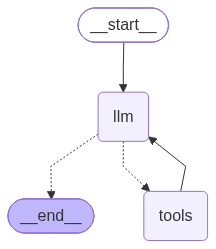

In [6]:
# ---- LLM Node ----
llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

# Add tools to the LLM
tools = [update_requirements]
llm_with_tools = llm.bind_tools(tools)

def llm_node(state: TravelState) -> dict:
    # Extract the current requirements from the state
    current_requirements = state["requirements"]
    requirements_context = SystemMessage(
        content=f"""
Current travel requirements:

{current_requirements}
"""
    )

    # Add the current requirements to the system prompt + messages
    messages = [
        SystemMessage(content=SYSTEM_PROMPT),
        requirements_context, 
        *state["messages"],
    ]

    response = llm_with_tools.invoke(messages)

    return {"messages": [response]}

# ---- Graph Builder ----
# Add short-term memory checkpointing
checkpointer = InMemorySaver()

builder = StateGraph(TravelState)

builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

graph = builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))

## Test with different prompts

### 1. Check requirements extraction

In [ ]:
# Same as phase1.ipynb, but now checking the requirements extracted by the agent
def test_prompt(prompt):
    config = {"configurable": {"thread_id": str(uuid.uuid4())}}

    result = graph.invoke({
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "requirements": None
    }, config)

    response = result["messages"][-1].content
    display(Markdown(response))

    return result

In [9]:
prompt = "I want to travel for 10 days in September with my partner. We are " \
    "leaving from Madrid, have a budget of €2,500, and we love hiking, nature " \
    "and good food. We don't want to rent a car. Where would you recommend?"
test1 = test_prompt(prompt)

Based on your requirements, here are a few destinations that fit your criteria well:

**1. Canary Islands (e.g., Tenerife or La Gomera)**
- **Why it fits:** Excellent hiking (volcanic landscapes, rainforests), mild weather in September, great food (local seafood and traditional dishes), and good public transport between towns and popular trailheads.
- **Budget:** Flights from Madrid are often affordable, and 10 days is doable within €2,500 total for two if you choose mid‑range accommodation.
- **No‑car note:** Island buses reach most major hiking areas; guided tours are also available.

**2. Galicia (Spain) – e.g., Santiago de Compostela, Rías Baixas, Cíes Islands**
- **Why it fits:** Coastal and inland hiking, lush green nature, outstanding seafood and wine. September is warm but not too hot.
- **Budget:** Train or bus from Madrid is inexpensive. Food and accommodation are reasonably priced.
- **No‑car note:** Public transport covers cities and some coastal routes; for remote trails you might join a guided group.

**3. Northern Portugal (Lisbon + Sintra, Algarve hiking)**
- **Why it fits:** Diverse hiking (Sintra hills, Rota Vicentina coastal trails), rich food culture, good transport links.
- **Budget:** Bus/train from Madrid to Lisbon is comfortable and affordable. Your budget covers 10 days comfortably.
- **No‑car note:** Excellent rail and bus network; many trails are accessible by public transport or guided walks.

**Next steps:**
- Do any of these appeal to you? I can help refine an itinerary.
- Alternatively, if you have a different region in mind (e.g., Pyrenees, Morocco), let me know and we can explore that.

Remember to verify flight/train prices and accommodation availability closer to your travel dates.

In [11]:
test1["requirements"]

TravelRequirements(origin='Madrid', destination=None, travel_dates='September', duration_days=10, travelers=2, budget=2500.0, currency='EUR', interests=['hiking', 'nature', 'good food'], constraints=['no car rental'])

Verify the agent's traces with LangSmith: https://smith.langchain.com

**Conclusion**: The agent extracted the user´s requirements and stored them in the graph state successfully using the update_requirements tool.

### 2. Verify that travel state persists and updates across interactions

In [22]:
def test_interaction(prompts):
    config = {"configurable": {"thread_id": str(uuid.uuid4())}}

    for i, prompt in enumerate(prompts, start=1):

        input_state = {
            "messages": [
                {"role": "user", "content": prompt}
            ]
        }

        # First turn needs to initialize requirements
        if i == 1:
            input_state["requirements"] = None

        result = graph.invoke(input_state, config)

        response = result["messages"][-1].content
        requirements = result["requirements"]

        display(Markdown(f"""
## Turn {i}

### User

{prompt}

### Travel Planner

{response}

### Travel Requirements

{requirements.model_dump_json(indent=2)}
"""))
        
    return result

In [23]:
prompt1 = "I want to travel for 10 days in September with my partner. " \
    "We are leaving from Madrid, have a budget of €2,500, and we love " \
    "hiking, nature and good food. We don't want to rent a car. " \
    "Where would you recommend?"

prompt2 = "Actually, we can only travel for 7 days and our budget has increased " \
    "to €3,500. We would also prefer a destination with some beaches."

prompt3 = "One more change: we are now willing to rent a car if it makes the trip " \
    "significantly better. We would also prefer somewhere less touristy."

test2 = test_interaction([prompt1, prompt2, prompt3])


## Turn 1

### User

I want to travel for 10 days in September with my partner. We are leaving from Madrid, have a budget of €2,500, and we love hiking, nature and good food. We don't want to rent a car. Where would you recommend?

### Travel Planner

Based on your requirements—10 days in September, traveling from Madrid with your partner, a budget of €2,500, interests in hiking, nature, and good food, and a no‑car‑rental constraint—I have some recommendations. These destinations are reachable by public transport (train or bus) and offer great hiking, natural beauty, and culinary highlights, all within your budget.

### 1. Asturias & Picos de Europa
- **Why**: Lush green mountains, the dramatic Picos de Europa range, coastal towns, and Asturian cuisine (cider,fabada, seafood). September is ideal for hiking.
- **Transport**: Direct high‑speed trains from Madrid to Oviedo/Gijón (≈2.5 h). Local buses and regional trains connect towns; some hiking trailheads are accessible by bus or organized shuttles.
- **Budget**: Mid‑range; you can find affordable rural casas, eat well, and use public transport without breaking the bank.

### 2. Basque Country (San Sebastián & Bilbao)
- **Why**: World‑class gastronomy (pintxos, Michelin‑starred restaurants), coastal walks, and nearby mountains (e.g., Jaizkibel). Nature is never far from the cities.
- **Transport**: High‑speed AVE from Madrid to San Sebastián or Bilbao (≈2.5–3 h). Both cities have excellent public transport and are gateways to coastal hikes.
- **Budget**: Slightly higher for dining, but you can balance with affordable accommodation and free hiking.

### 3. Catalonia (Pyrenees & Barcelona)
- **Why**: Combine Barcelona’s food scene with Pyrenean hiking. The Catalan Pyrenees offer well‑marked trails, valleys, and mountain refuges.
- **Transport**: AVE to Barcelona (≈2.5 h), then regional buses or trains to trailheads (e.g., La Seu d’Urgell, Ribes de Freser).
- **Budget**: Varied; you can opt for budget‑friendly hostels in Barcelona and simpler mountain lodges.

### 4. Galicia (Rías Baixas & Santiago de Compostela)
- **Why**: Coastal hiking (Caminho dos Faros), green hills, and exceptional seafood/wine. The Camino de Santiago passes through beautiful countryside.
- **Transport**: Train or flight to Santiago (≈2–3 h). Buses connect coastal villages; some hiking is accessible from towns without a car.
- **Budget**: Very reasonable; Galicia offers great value for food and accommodation.

### 5. Northern Portugal (Porto & Peneda‑Gerês National Park)
- **Why**: Porto’s food and wine, plus the rugged Gerês mountains for hiking. September weather is pleasant.
- **Transport**: Flight or train to Porto (≈2 h flight). Buses from Porto to Gerês park (≈1.5 h). Within the park, local buses or guided tours can reach trailheads.
- **Budget**: Portugal is generally affordable, and your budget should cover comfortable travel and meals.

### Next Steps
To refine these suggestions, I’d like to know:
- **Do you prefer coastal or mountain scenery?**  
- **How “remote” do you want the hiking to be?** (e.g., wild trails vs. well‑marked routes with cafés nearby)
- **Any dietary preferences or must‑try foods?**

Let me know, and I can tailor a more detailed itinerary or focus on one or two destinations that best match your vibe.

### Travel Requirements

{
  "origin": "Madrid",
  "destination": null,
  "travel_dates": "September",
  "duration_days": 10,
  "travelers": 2,
  "budget": 2500.0,
  "currency": "EUR",
  "interests": [
    "hiking",
    "nature",
    "good food"
  ],
  "constraints": [
    "no car rental"
  ]
}



## Turn 2

### User

Actually, we can only travel for 7 days and our budget has increased to €3,500. We would also prefer a destination with some beaches.

### Travel Planner

Excellent—thanks for clarifying! With **7 days** and a **€3,500 budget** (for two), you have more flexibility to focus on a destination that blends **beaches, hiking, nature, and great food**, all without a car. Here are my top picks:

---

### 1. **Basque Country (San Sebastián + coastal villages)**
- **Why**: San Sebastián’s La Concha beach is one of Europe’s finest urban beaches, and nearby Zurriola is popular for surfing. The coastal hills (Jaizkibel, Urgull) offer easy hikes with sea views. The Basque culinary scene is legendary—pintxos, Michelin‑starred restaurants, and traditional cider houses.
- **Transport**: AVE from Madrid to San Sebastián (≈2.5 h). Local buses connect to nearby towns (Hondarribia, Getaria, Zarautz) and trailheads. No car needed.
- **Budget**: You can enjoy mid‑range to upscale dining and comfortable hotels well within €3,500 for 7 days.
- **Suggested mix**: 3 days San Sebastián (beaches, city hikes, food tours), 2 days coastal villages (beach hikes, seafood), 2 days inland Basque Country (mountains, rural cuisine).

### 2. **Catalonia (Costa Brava + Barcelona)**
- **Why**: Costa Brava’s cliff‑lined coves and sandy beaches are stunning, and the coastal paths (Camí de Ronda) are perfect for day hikes. Barcelona adds urban beaches, Gaudí, and a vibrant food scene (Boqueria market, tapas bars).
- **Transport**: AVE to Barcelona (≈2.5 h), then regional trains or buses to coastal towns (Tossa de Mar, Calella de Palafrugell, Roses). Well‑connected by public transport.
- **Budget**: Mid‑range; you can balance city stays with coastal guesthouses.
- **Suggested mix**: 3 days Barcelona (beaches, city hikes, food), 4 days Costa Brava (beach hikes, kayaking, seafood dinners).

### 3. **Asturias & Picos de Europa**
- **Why**: If you prefer rugged, unspoiled beaches (Playa de Gulpiyuri, Playa de Las Catedrales) alongside dramatic mountain hiking, Asturias delivers. The cuisine is hearty (fabada, cider, seafood).
- **Transport**: Train to Oviedo/Gijón (≈2.5 h). Local buses reach coastal villages and Picos de Europa trailheads (some require a taxi for final access, but tours are available).
- **Budget**: Very affordable; you’ll get excellent value for accommodation and meals.
- **Suggested mix**: 2 days coast (beaches, coastal walks), 3 days Picos (mountain hikes, villages), 2 days Gijón/Oviedo (city beaches, food markets).

### 4. **Northern Portugal (Porto + Gerês + coast)**
- **Why**: Porto’s urban beaches (Foz) and nearby seaside towns (Vila Nova de Gaia, Espinho) offer a mix of city and coast. The Peneda‑Gerês National Park is a hiking paradise, and Portuguese cuisine (seafood, pastries) is a delight.
- **Transport**: Flight to Porto (≈2 h from Madrid). Buses to Gerês (≈1.5 h) and coastal towns; guided hikes can be arranged without a car.
- **Budget**: Portugal is still very reasonable; your budget will cover nice hotels and meals.
- **Suggested mix**: 2 days Porto (city beach, food tours), 3 days Gerês (hiking, nature), 2 days coastal villages (beaches, relaxation).

---

### Which direction feels right?
- **If food is your top priority**: Basque Country or Catalonia.
- **If you want wilder, less‑crowded beaches + mountains**: Asturias or Galicia.
- **If you’d like a mix of city buzz and coastal/nature escapes**: Porto or Barcelona.

Let me know if you’d like me to flesh out a day‑by‑day outline for any of these, or if you have another region in mind!

### Travel Requirements

{
  "origin": "Madrid",
  "destination": null,
  "travel_dates": "September",
  "duration_days": 7,
  "travelers": 2,
  "budget": 3500.0,
  "currency": "EUR",
  "interests": [
    "hiking",
    "nature",
    "good food",
    "beaches"
  ],
  "constraints": [
    "no car rental"
  ]
}



## Turn 3

### User

One more change: we are now willing to rent a car if it makes the trip significantly better. We would also prefer somewhere less touristy.

### Travel Planner

Excellent! With the flexibility to rent a car and a focus on **less touristy** destinations, we can explore some truly special spots that are harder to reach by public transport but offer rewarding drives through stunning scenery. Here are my top picks, all blending beaches, hiking, nature, and fantastic food while avoiding the crowds:

---

### 1. **Asturias & Picos de Europa** *(still my top recommendation)*
- **Why it fits**: Asturias remains one of Spain’s least‑touristed coastal regions, with wild, empty beaches (Playa de Las Catedrales, Playa de San Antonio) and the dramatic Picos de Europa mountains. September weather is perfect for hiking, and the local cuisine (cider, fabada, fresh seafood) is hearty and authentic.
- **Car advantage**: A rental car lets you explore hidden coastal villages (Cudillero, Lastres) and drive into the heart of the Picos, where many trailheads are only accessible by road. You can also visit remote alpine lakes (Lagos de Covadonga) without relying on infrequent buses.
- **Budget**: Very affordable; you’ll get excellent value for accommodation, food, and the car rental.

### 2. **Galicia (Rías Baixas & inland)**
- **Why it fits**: Galicia is Spain’s green, misty northwest—far less visited than the Mediterranean coast. It offers secluded rías (inlets) with sandy beaches, lush forests, and a unique Celtic‑influenced culture. The seafood (pulpo a la gallega, percebes) is among the best in Europe.
- **Car advantage**: The Rías Baixas (e.g., Ría de Arousa, Ría de Vigo) are best explored by car, hopping between fishing villages, wineries, and hidden beaches. Inland, you can drive to the Sil River canyon (Ribeira Sacra) for vineyard hikes.
- **Budget**: One of the most affordable regions in Spain; your budget will go far.

### 3. **Northern Portugal (Peneda‑Gerês + Costa Verde)**
- **Why it fits**: Portugal’s only national park (Gerês) is a wild, granite mountain landscape with waterfalls, hiking trails, and traditional villages. The nearby Costa Verde (from Porto to the Spanish border) has beautiful, often‑empty beaches.
- **Car advantage**: Gerês is not well‑served by public transport; a car is essential to reach trailheads and remote villages. You can also drive to the Alvão Natural Park and the historic town of Bragança.
- **Budget**: Portugal is still very affordable, and your budget will cover a comfortable car rental and nice accommodations.

### 4. **Catalonia (Pyrenees & hidden Costa Brava)**
- **Why it fits**: While Barcelona and the central Costa Brava are busy, the northern Costa Brava (Cap de Creus) and the Catalan Pyrenees are quieter. You’ll find rugged coves, medieval villages, and mountain trails without the summer crowds.
- **Car advantage**: A car lets you reach the wild Cap de Creus peninsula, the volcanic Garrotxa region, and the high Pyrenean valleys (Vall de Núria, Vall de Boí) where bus connections are limited.
- **Budget**: Moderate; the Pyrenean valleys are cheaper than the coast.

---

### How would you like to proceed?
- **Do you want a day‑by‑day itinerary for one of these destinations?**
- **Would you like me to compare estimated costs (car rental, accommodation, food) for each option?**
- **Or is there a particular vibe (mountains vs. coast, food focus vs. adventure) you’d like to prioritize?**

Let me know, and I’ll craft a more detailed plan!

### Travel Requirements

{
  "origin": "Madrid",
  "destination": null,
  "travel_dates": "September",
  "duration_days": 7,
  "travelers": 2,
  "budget": 3500.0,
  "currency": "EUR",
  "interests": [
    "hiking",
    "nature",
    "good food",
    "beaches",
    "less touristy"
  ],
  "constraints": []
}


The agent updates successfully the `TravelState` when receiving new requirements across several prompts.